# Análise exploratória — Vítimas de intervenção policial no Município do Rio de Janeiro (1º quadrimestre, 2003–2022)

**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · **Período:** 6º · **Curso:** Bacharelado em Sistemas de Informação · **Instituição:** Unilasalle RJ
**Autor:** Miguel Garcia Lopes do Amaral · **Professor orientador:** Alexandre Neves Louzada
**Fonte dos dados:** ISP-RJ / DATA.RIO, Tabela 2300 · **Dicionário:** [`data/data_dictionary.md`](../data/data_dictionary.md)

Este notebook documenta a exploração, a prototipação e a validação das análises do artigo (`docs/index.html`). Toda a lógica reutilizável está em `src/` (`etl.py`, `analysis.py`, `figures.py`); o notebook a **chama e comenta**, de modo que notebook, artigo e `metricas_agregadas.json` não divergem.

## Perguntas de pesquisa
* **RQ1.** A série 2003–2022 apresenta tendência monotônica de queda ou, em vez disso, mudanças de patamar (quebra estrutural)?
* **RQ2.** Normalizar pela população (taxa por 100 mil habitantes) altera a leitura temporal obtida com a contagem absoluta?
* **RQ3.** Quais variações interanuais são atípicas — inclusive frente ao ruído esperado de uma contagem aleatória — e a volatilidade difere entre regimes?

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import etl, analysis, figures

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
figures.setup()
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 1. Ingestão e auditoria de qualidade
O ETL (`src/etl.py`) lê o `.xls` bruto **sem alterá-lo**, localiza as linhas de dados pelo conteúdo, converte o token `..` ("não se aplica dado numérico") em nulo, tipa as colunas, recalcula as métricas derivadas e **interrompe** se alguma métrica publicada divergir da recalculada. Abaixo reexecuto o pipeline e examino o resultado.

In [2]:
etl.run()               # lê data/raw, valida e grava data/processed
df = etl.load_processed()  # análises sempre partem do arquivo tratado (fonte única da verdade)
log = json.loads((etl.OUT_DEFAULT / "etl_log.json").read_text(encoding="utf-8"))
print("SHA-256 do bruto :", log["sha256_bruto"])
print("Linhas de dados   :", log["linhas_de_dados"], "| período:", log["periodo"])
print("Desvios publicado × recalculado:", {k: v for k, v in log["validacao"].items() if k.startswith("max_")})
print("Nulos por coluna  :", log["validacao"]["nulos_por_coluna"])
df.dtypes.to_frame("tipo")

SHA-256 do bruto : 179553629368d5962295634ed9eeb118cb0b1188d6ddf7f02a854182fa7b2d35
Linhas de dados   : 20 | período: [2003, 2022]
Desvios publicado × recalculado: {'max_desvio_dif_abs': 0.0, 'max_desvio_dif_pct': 0.0, 'max_desvio_taxa_100mil': 0.0, 'max_desvio_media_mensal': 0.0}
Nulos por coluna  : {'dif_abs_publicada': 1, 'dif_pct_publicada': 1, 'dif_abs_calc': 1, 'dif_pct_calc': 1}


,tipo
ano,int64
vitimas_jan_abr,int64
dif_abs_publicada,float64
dif_pct_publicada,float64
populacao,float64
taxa_100mil_publicada,float64
media_mensal_publicada,float64
dif_abs_calc,float64
dif_pct_calc,float64
taxa_100mil_calc,float64


In [3]:
df.head(8)

,ano,vitimas_jan_abr,dif_abs_publicada,dif_pct_publicada,populacao,taxa_100mil_publicada,media_mensal_publicada,dif_abs_calc,dif_pct_calc,taxa_100mil_calc,media_mensal_calc,indice_vitimas_base100,indice_taxa_base100,indice_populacao_base100
0,2003,291,NaN,NaN,5.866e+06,4.961,72.75,NaN,NaN,4.961,72.75,100.000,100.000,100.000
1,2004,203,-88.0,-30.241,6.027e+06,3.368,50.75,-88.0,-30.241,3.368,50.75,69.759,67.889,102.756
2,2005,190,-13.0,-6.404,6.073e+06,3.128,47.50,-13.0,-6.404,3.128,47.50,65.292,63.060,103.539
3,2006,205,15.0,7.895,6.120e+06,3.350,51.25,15.0,7.895,3.350,51.25,70.447,67.523,104.329
4,2007,288,83.0,40.488,6.166e+06,4.670,72.00,83.0,40.488,4.670,72.00,98.969,94.144,105.125
5,2008,331,43.0,14.931,6.213e+06,5.327,82.75,43.0,14.931,5.327,82.75,113.746,107.381,105.927
6,2009,227,-104.0,-31.420,6.261e+06,3.626,56.75,-104.0,-31.420,3.626,56.75,78.007,73.084,106.735
7,2010,212,-15.0,-6.608,6.306e+06,3.362,53.00,-15.0,-6.608,3.362,53.00,72.852,67.768,107.502


**Leitura.** Os 20 anos são contíguos e a fonte é internamente consistente (desvio máximo igual a zero em todas as métricas comparadas). O único nulo é a variação de 2003 (não há 2002 na tabela). Nenhuma linha foi removida nem imputada.

## 2. Estatística descritiva

In [4]:
desc = pd.DataFrame({
    "vítimas": analysis.descritivas(df["vitimas_jan_abr"]),
    "taxa/100 mil": analysis.descritivas(df["taxa_100mil_calc"]),
})
desc

,vítimas,taxa/100 mil
n,20.000,20.000
media,185.950,2.930
desvio_padrao,72.017,1.194
coef_variacao,0.387,0.408
minimo,77.000,1.199
q1,120.000,1.788
mediana,196.500,3.189
q3,227.000,3.381
maximo,331.000,5.327
iqr,107.000,1.594


A média de ≈186 vítimas por quadrimestre esconde uma dispersão grande (CV ≈ 39 %; amplitude de 77 a 331). A mediana (196,5) é próxima da média e a assimetria é baixa (≈ 0,2): o problema não é uma cauda longa, e sim **patamares distintos** ao longo do tempo — o que motiva RQ1.

## 3. RQ1 — Tendência monotônica *versus* mudança de patamar

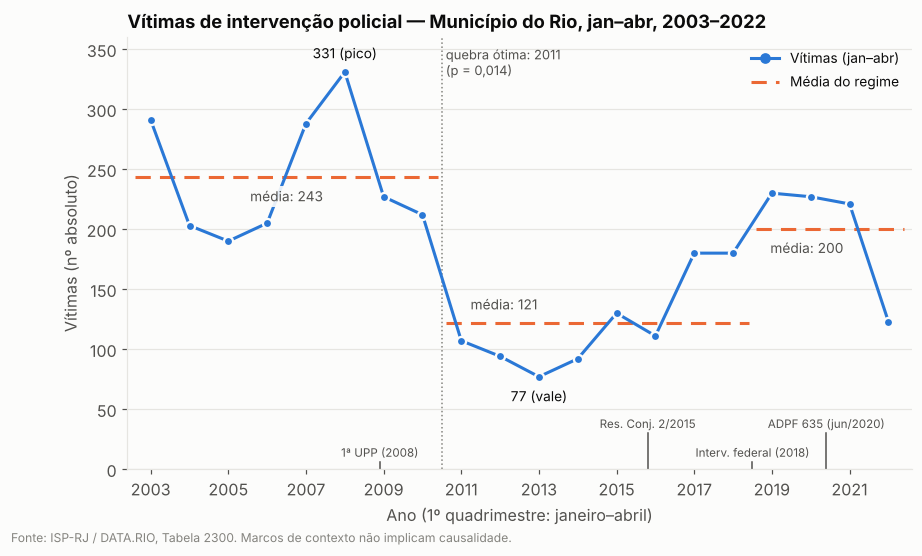

In [5]:
fig = figures.fig_serie(df, analysis.compute(df)); None

In [6]:
t = analysis.tendencia(df)
print(f"Kendall τ = {t['kendall_tau']:.3f} (p = {t['kendall_p']:.3f})")
print(f"Theil–Sen: {t['theil_sen_inclinacao']:.2f} vítimas/ano  IC95% [{t['theil_sen_ic95'][0]:.2f}; {t['theil_sen_ic95'][1]:.2f}]")

Kendall τ = -0.159 (p = 0.330)
Theil–Sen: -3.92 vítimas/ano  IC95% [-10.89; 1.94]


Não há evidência de **tendência monotônica** (τ ≈ −0,16; p ≈ 0,33; o IC95 % da inclinação de Theil–Sen inclui zero). Isso não contradiz a impressão visual de queda: a série cai, **mas depois volta a subir**, o que um teste monotônico penaliza. Testei então uma **quebra única** de nível (mínimo de SSE) com significância por permutação — refazendo a busca do melhor ponto em cada permutação, para não inflar o resultado por "escolher o melhor corte".

In [7]:
q = analysis.quebra_unica(df)
pd.Series(q).to_frame("valor")

,valor
ano_inicio_segmento2,2011.000
media_segmento1,243.375
media_segmento2,147.667
reducao_percentual_medias,-39.325
r2_dois_niveis,0.446
p_permutacao,0.014
n_permutacoes,20000.000
semente,2022.000


In [8]:
reg = pd.DataFrame(analysis.regimes(df)).set_index("regime")[["n", "media", "mediana", "desvio_padrao", "coef_variacao", "minimo", "maximo"]]
reg

,n,media,mediana,desvio_padrao,coef_variacao,minimo,maximo
regime,,,,,,,
2003–2010,8,243.375,219.5,52.293,0.215,190.0,331.0
2011–2018,8,121.375,109.0,39.359,0.324,77.0,180.0
2019–2022,4,200.250,224.0,51.636,0.258,123.0,230.0


In [9]:
pd.DataFrame(analysis.comparar_regimes(df)).T.rename(columns={"p": "p (Mann–Whitney, bilateral)"})

,U,"p (Mann–Whitney, bilateral)"
2003–2010 vs 2011–2018,64.0,9.310e-04
2003–2010 vs 2019–2022,18.5,7.336e-01
2011–2018 vs 2019–2022,3.0,3.344e-02


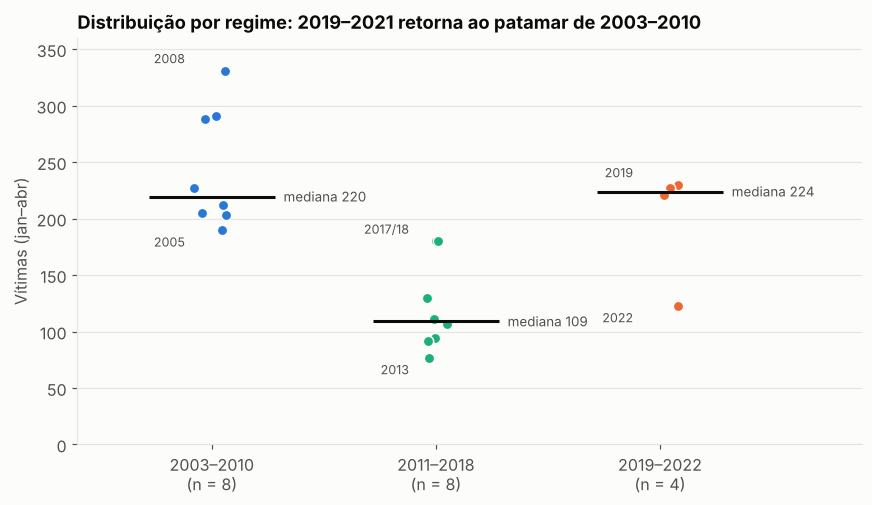

In [10]:
figures.fig_regimes(df, analysis.compute(df)); None

**O que encontrei (RQ1).** A quebra ótima ocorre em **2011** (médias 243 → 148; R² de dois níveis ≈ 0,45; p de permutação ≈ 0,014). Porém o segundo segmento mistura dois comportamentos: **2011–2018** (média 121) e **2019–2022** (média 200). O primeiro e o terceiro regimes **não diferem** (Mann–Whitney p ≈ 0,73), enquanto 2011–2018 difere de ambos. Ou seja: *queda de patamar em 2011, retorno ao patamar anterior em 2019*, e novo recuo em 2022 (123).

> **Um aviso honesto.** Os regimes de 3 trechos foram definidos **após** olhar os dados (exploratório); os p-valores de Mann–Whitney são, portanto, otimistas. A quebra única é o teste "honesto" (permutação com busca refeita).

### Sensibilidade da quebra a escolhas de análise

In [11]:
rows = []
base = df.copy()
for nome, d in [("completa (min. 3 anos por trecho)", base),
                ("sem 2022 (ano mais recente)", base[base.ano != 2022].reset_index(drop=True)),
                ("sem 2008 (pico)", base[base.ano != 2008].reset_index(drop=True))]:
    r = analysis.quebra_unica(d)
    rows.append({"cenário": nome, "ano da quebra": r["ano_inicio_segmento2"],
                 "média antes": r["media_segmento1"], "média depois": r["media_segmento2"],
                 "R²": r["r2_dois_niveis"], "p (permutação)": r["p_permutacao"]})
for ms in (2, 4):
    r = analysis.quebra_unica(base, min_seg=ms)
    rows.append({"cenário": f"min. {ms} anos por trecho", "ano da quebra": r["ano_inicio_segmento2"],
                 "média antes": r["media_segmento1"], "média depois": r["media_segmento2"],
                 "R²": r["r2_dois_niveis"], "p (permutação)": r["p_permutacao"]})
pd.DataFrame(rows).set_index("cenário")

,ano da quebra,média antes,média depois,R²,p (permutação)
cenário,,,,,
completa (min. 3 anos por trecho),2011,243.375,147.667,0.446,0.014
sem 2022 (ano mais recente),2011,243.375,149.909,0.429,0.022
sem 2008 (pico),2011,230.857,147.667,0.400,0.030
min. 2 anos por trecho,2011,243.375,147.667,0.446,0.014
min. 4 anos por trecho,2011,243.375,147.667,0.446,0.013


A quebra em 2011 é **estável** nos cinco cenários (mesmo ano) e o p de permutação permanece abaixo de 0,05 (0,013–0,030), embora varie ao excluir pontos influentes — como esperado com *n* = 20.

## 4. RQ2 — Contagem *versus* taxa por 100 mil habitantes

In [12]:
r2 = analysis.contagem_vs_taxa(df)
resumo = pd.DataFrame({
    "início (2003)": [r2["vitimas_inicial"], r2["taxa_inicial"], r2["populacao_inicial"]],
    "fim (2022)": [r2["vitimas_final"], r2["taxa_final"], r2["populacao_final"]],
    "variação %": [r2["var_pct_vitimas"], r2["var_pct_taxa"], r2["var_pct_populacao"]],
    "CAGR % a.a.": [r2["cagr_vitimas_pct"], r2["cagr_taxa_pct"], r2["cagr_populacao_pct"]],
}, index=["vítimas", "taxa / 100 mil", "população"])
resumo

,início (2003),fim (2022),variação %,CAGR % a.a.
vítimas,2.910e+02,1.230e+02,-57.732,-4.431
taxa / 100 mil,4.961e+00,1.814e+00,-63.443,-5.159
população,5.866e+06,6.782e+06,15.623,0.767


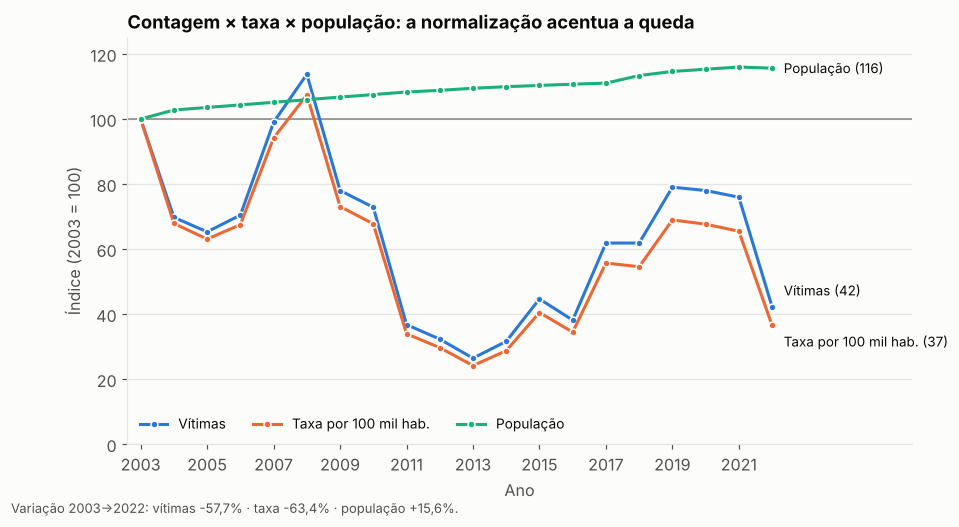

In [13]:
figures.fig_indices(df, analysis.compute(df)); None

In [14]:
print("Decomposição logarítmica (Δln taxa = Δln vítimas − Δln população):")
print({k: round(v, 4) for k, v in r2["decomposicao_log"].items()})
print(f"Spearman vítimas×taxa      ρ = {r2['spearman_vitimas_taxa']['rho']:.3f} (p = {r2['spearman_vitimas_taxa']['p']:.1e})")
print(f"Spearman vítimas×população ρ = {r2['spearman_vitimas_populacao']['rho']:.3f} (p = {r2['spearman_vitimas_populacao']['p']:.2f})")
print("Maior mudança de posição no ranking anual (vítimas vs taxa):", r2["max_dif_posicao_ranking"])
print("Pico / vale — vítimas:", r2["ano_pico_vitimas"], "/", r2["ano_vale_vitimas"], "| taxa:", r2["ano_pico_taxa"], "/", r2["ano_vale_taxa"])

Decomposição logarítmica (Δln taxa = Δln vítimas − Δln população):
{'delta_ln_vitimas': -0.8611, 'delta_ln_populacao': 0.1452, 'delta_ln_taxa': -1.0063, 'parcela_populacao_pct': 14.4257}
Spearman vítimas×taxa      ρ = 0.973 (p = 6.8e-13)
Spearman vítimas×população ρ = -0.265 (p = 0.26)
Maior mudança de posição no ranking anual (vítimas vs taxa): 4
Pico / vale — vítimas: 2008 / 2013 | taxa: 2008 / 2013


**O que encontrei (RQ2).** A população do município cresceu ≈ 15,6 % (0,77 % a.a.). Em consequência, a queda da **taxa** (−63,4 %) é mais intensa que a da **contagem** (−57,7 %): ≈ 14 % da queda logarítmica da taxa se deve apenas ao crescimento populacional. Porém, a **leitura temporal não muda**: ρ de Spearman entre contagem e taxa ≈ 0,97; picos (2008) e vales (2013) coincidem; nenhum ano muda mais que 4 posições no ranking. A normalização importa para a **magnitude** (≈ 5,7 pontos percentuais), não para o **padrão**. A população, por si, não explica a série (ρ ≈ −0,26; p ≈ 0,26).

## 5. RQ3 — Variações interanuais atípicas e volatilidade

In [15]:
v = analysis.variacoes_atipicas(df)
tab = pd.DataFrame(v["tabela"]).set_index("ano")
tab.round(3)

,var_pct,z_mod,tukey,z35,z_poisson,p_bonf
ano,,,,,,
2004,-30.241,-1.059,False,False,-3.959,0.001
2005,-6.404,-0.144,False,False,-0.656,1.000
2006,7.895,0.404,False,False,0.755,1.000
2007,40.488,1.655,False,False,3.738,0.004
2008,14.931,0.674,False,False,1.728,1.000
2009,-31.420,-1.104,False,False,-4.403,0.000
2010,-6.608,-0.152,False,False,-0.716,1.000
2011,-49.528,-1.800,False,False,-5.879,0.000
2012,-12.150,-0.365,False,False,-0.917,1.000


In [16]:
print("Tukey (1,5·IQR) :", v["anos_tukey"] or "nenhum ano", "| cerca:", [round(x, 1) for x in v["cerca_tukey"]])
print("z modificado >3,5:", v["anos_z_modificado"] or "nenhum ano")
print("Acima do ruído de Poisson (Bonferroni, p<0,05):", v["anos_acima_ruido_poisson"])

Tukey (1,5·IQR) : nenhum ano | cerca: [-66.7, 67.5]
z modificado >3,5: nenhum ano
Acima do ruído de Poisson (Bonferroni, p<0,05): [2004, 2007, 2009, 2011, 2017, 2022]


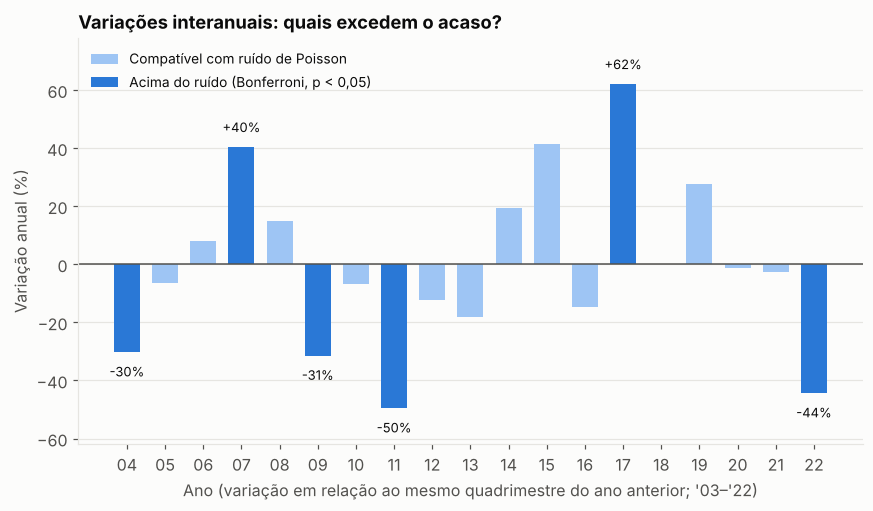

In [17]:
figures.fig_variacoes(df, analysis.compute(df)); None

In [18]:
pd.DataFrame(analysis.volatilidade_por_regime(df)).set_index("regime")

,n,media_abs_var_pct,mediana_abs_var_pct,desvio_padrao_var_pct
regime,,,,
2003–2010,7,19.712,14.931,25.470
2011–2018,8,27.166,18.783,35.835
2019–2022,4,19.017,15.210,29.673


**O que encontrei (RQ3).** Medidas robustas **baseadas na própria série** (Tukey, z modificado) não apontam nenhum ano atípico: variações de ±30–60 % são *normais* nesta série (mediana das |variações| ≈ 15–19 %). Já o teste contra o **ruído de Poisson** — que pergunta se a variação excede o que o puro acaso de uma contagem pequena produziria — sinaliza **6 de 19** transições: 2004, 2007, 2009, 2011, 2017 e 2022. A volatilidade (|Δ%| médio) é maior em 2011–2018 (27,2 %), mas, com poucos pontos, não há como afirmar diferença entre regimes.

## 6. Exportação das métricas e das figuras do artigo

In [19]:
m = analysis.compute(df)
saida = etl.OUT_DEFAULT / "metricas_agregadas.json"
saida.write_text(json.dumps(m, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
paths = figures.build_all()
print("Métricas:", saida.relative_to(etl.ROOT))
for p in paths:
    print("Figura  :", p.relative_to(etl.ROOT))

Métricas: data/processed/metricas_agregadas.json
Figura  : docs/assets/fig1_serie_temporal.png
Figura  : docs/assets/fig2_indices_taxa_populacao.png
Figura  : docs/assets/fig3_variacoes_interanuais.png
Figura  : docs/assets/fig4_distribuicao_regimes.png


## 7. Conclusões e limitações
1. **Padrão principal:** não é uma queda linear, e sim **três patamares** (alto → baixo em 2011 → retorno ao alto em 2019 → recuo em 2022).
2. **Normalização por população** reforça a queda, mas não altera o padrão temporal.
3. **Variações grandes são a regra**; 6 de 19 excedem o ruído de Poisson.
4. **Limitações:** *n* = 20; só o 1º quadrimestre; agregado municipal; registros policiais com classificação provisória; regimes definidos *a posteriori*; **correlação temporal não implica causalidade** (marcos como UPPs, intervenção federal e ADPF 635 são contexto, não explicação testada).